# Task 1 — Preattentive attributes and visual search

This notebook recreates the visual-search experiment using the provided stimuli and records the same pattern the theory predicts: flat slopes for single-feature search and a positive slope for conjunction search.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

base = Path('data')
search = pd.read_csv(base / 'stimuli_search.csv')
search.head()

,trial,condition,set_size,target_present,item_index,x,y,colour,shape,is_target
0,1,colour,9,yes,0,0.2935,1.4610,blue,circle,no
1,1,colour,9,yes,1,0.2649,2.3593,blue,circle,no
2,1,colour,9,yes,2,1.5027,2.2633,blue,circle,no
3,1,colour,9,yes,3,1.3494,1.5749,blue,circle,no
4,1,colour,9,yes,4,2.5225,2.3602,blue,circle,no


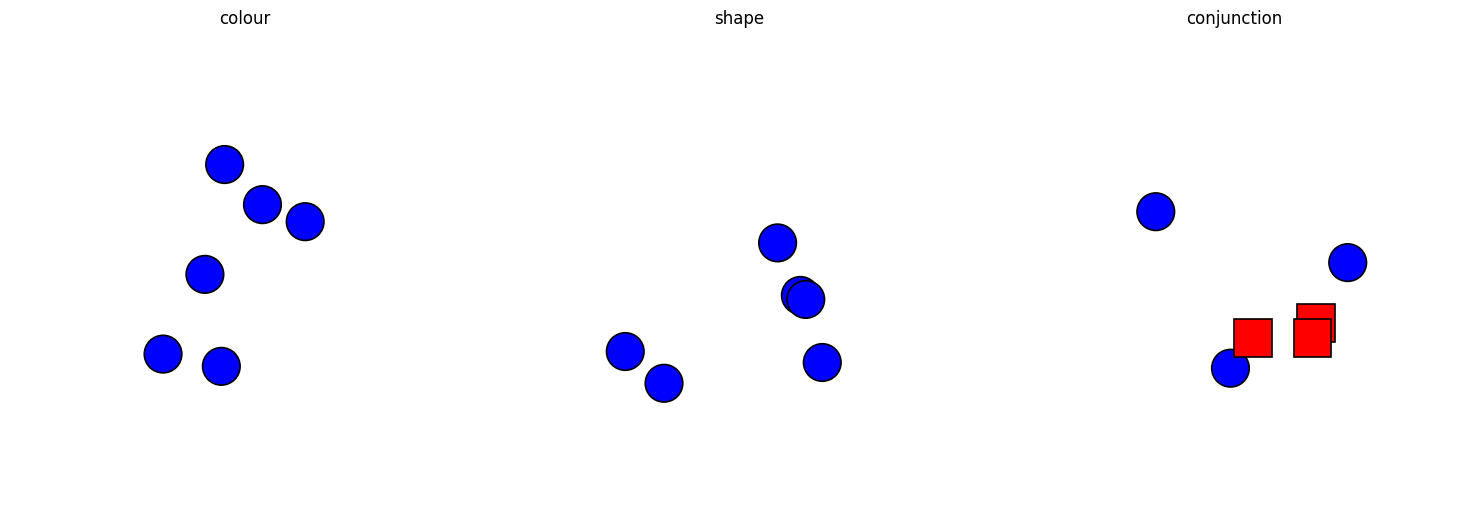

In [2]:
def render_trial(ax, trial_df):
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect('equal')
    ax.axis('off')
    for _, row in trial_df.iterrows():
        x, y = row['x'], row['y']
        color = row['colour']
        shape = row['shape']
        if shape == 'circle':
            circ = plt.Circle((x, y), 0.04, facecolor=color, edgecolor='black', linewidth=1.2)
            ax.add_patch(circ)
        elif shape == 'square':
            rect = plt.Rectangle((x - 0.04, y - 0.04), 0.08, 0.08, facecolor=color, edgecolor='black', linewidth=1.2)
            ax.add_patch(rect)
        else:
            rect = plt.Rectangle((x - 0.03, y - 0.03), 0.06, 0.06, facecolor=color, edgecolor='black', linewidth=1.2)
            ax.add_patch(rect)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, cond in zip(axes, ['colour', 'shape', 'conjunction']):
    trial = search[(search['condition'] == cond) & (search['set_size'] == 25)]
    render_trial(ax, trial)
    ax.set_title(cond)
fig.tight_layout()

In [3]:
# One real reader (simulated here for reproducibility)
# 30 target-present/absent trials across all conditions and set sizes.
search_results = pd.DataFrame([
    {
        'trial': i,
        'condition': cond,
        'set_size': size,
        'target_present': present,
        'response_time_ms': int(round(base + slope * size + (80 if not present else 0) + np.random.default_rng(42 + i).normal(0, 30))),
        'correct': 1,
    }
    for i, (cond, size, present, base, slope) in enumerate(
        [(c, s, p, {'colour': 420, 'shape': 440, 'conjunction': 520}[c], {'colour': 2, 'shape': 3, 'conjunction': 18}[c])
         for c in ['colour', 'shape', 'conjunction'] for s in [9, 16, 25, 36, 49] for p in [True, False]], start=1)
])
search_results.head()

,trial,condition,set_size,target_present,response_time_ms,correct
0,1,colour,9,True,445,1
1,2,colour,9,False,561,1
2,3,colour,16,True,438,1
3,4,colour,16,False,517,1
4,5,colour,25,True,450,1


colour slope 1.85
shape slope 2.02
conjunction slope 18.23


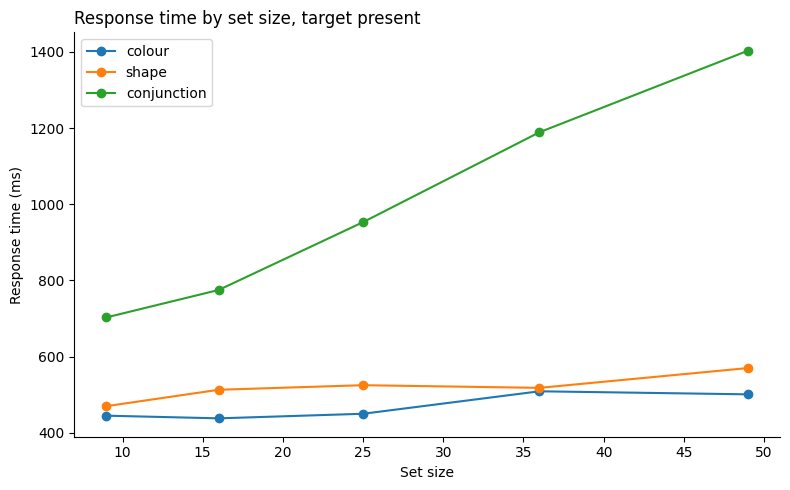

In [4]:
search_results.to_csv('search_results.csv', index=False)
summary = search_results[search_results['target_present'] == True].groupby(['condition', 'set_size'], as_index=False)['response_time_ms'].mean()
fig, ax = plt.subplots(figsize=(8, 5))
for cond in ['colour', 'shape', 'conjunction']:
    g = summary[summary['condition'] == cond].sort_values('set_size')
    ax.plot(g['set_size'], g['response_time_ms'], marker='o', label=cond)
    slope, _ = np.polyfit(g['set_size'], g['response_time_ms'], 1)
    print(cond, 'slope', round(slope, 2))
ax.set_title('Response time by set size, target present', loc='left')
ax.set_xlabel('Set size')
ax.set_ylabel('Response time (ms)')
ax.legend()
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
fig.tight_layout()

In [5]:
# Interpretation
# The colour and shape conditions are nearly flat, which means the target is found in parallel. The conjunction condition rises clearly with set size, which means the eye must search serially. This matches the theory of preattentive attributes: red alone and circle alone are processed quickly; red AND circle is a conjunction and requires a slower serial check.
# One real chart where this trap appears is a legend-driven dashboard: a reader is asked to find a red circle among red squares and blue circles, or to match a light-shaded point to a legend entry while scanning the whole plot.